# Part 5f: does local house price growth explain who keeps or loses affordability?

Begley and Reina (Journal of Housing Economics, 2014) study owners of New York's Mitchell-Lama properties and find that the strongest drivers of opting out are
neighborhood price appreciation (relative to the city, over the prior five years), for-profit ownership, and being past all affordability restrictions. Part 5c tested a related idea, the gap between the market
rent and the restricted rent, and found nothing. Appreciation is a different measure: it is the owner's gain from selling or converting, not the current rent level.

**Measure.** FHFA all-transactions house price index by county (`src/clean_fhfa_hpi.py`, 2,795 counties). For rescue events the growth over the five years ending the year before the lapse,
taken relative to all events in the same year (so the national price cycle drops out, as in Begley and Reina) and within state. For LIHTC projects the growth over the five and ten years ending 2023.

**Tests.** (1) HOME and HUD-program rescue (Part 5 events) with the price growth added; (2) LIHTC exit (Part 5b sample) with the price growth added. State effects, state-clustered standard errors.
**Timing caveat for LIHTC:** exit is observed only as of 2024, not dated, so the growth window cannot be lined up with the decision, unlike the hazard model of Begley and Reina.

In [1]:
import sys, warnings
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

import preservation as P
from viz import apply_style, SERIES, save_figure, BASELINE, dot

apply_style()
pd.set_option("display.width", 220)
hpi = pd.read_csv("data/interim/fhfa_hpi_county.csv", dtype={"county_fips": str})
cov = hpi[hpi.year.between(2010, 2025)].groupby("year").agg(counties=("county_fips", "nunique"), median_5y_growth=("growth_5y_pct", "median"), share_missing=("growth_5y_pct", lambda s: s.isna().mean()))
display(cov.round(2).loc[[2010, 2015, 2019, 2021, 2023, 2025]])

,counties,median_5y_growth,share_missing
year,,,
2010,2764,4.94,0.01
2015,2776,3.12,0.01
2019,2779,19.69,0.01
2021,2795,29.32,0.01
2023,2795,49.83,0.05
2025,2795,53.12,0.04


## 1. HOME and HUD-program rescue

Same 12,822 events as Part 5. Each event takes the county's five-year price growth ending the year before the lapse. Specifications: state effects only; state and event-year effects (the main one); and with the size and program controls. Then the out-of-sample check on the two time splits.

In [2]:
ev = P.add_price_growth(P.build_events())
d = ev.dropna(subset=["price_growth_within"]).copy()
print(f"events with a county price index: {len(d)} of {len(ev)} ({len(d) / len(ev):.1%}); rescued {int(d.resub_3y.sum())}")
base_cols = ["log_total_units"] + [f"g_{x}" for x in P.GROUPS if x != "home_only"]

def fe_rescue(df, col, year_fe=True, controls=True):
    v = df.groupby("state_fips").resub_3y.agg(["sum", "size"]); keep = v[(v["sum"] > 0) & (v["size"] >= 30)].index
    x = df[df.state_fips.isin(keep)]
    parts = [x[(base_cols if controls else []) + [col]].astype(float), pd.get_dummies(x.state_fips, drop_first=True, dtype=float)] + ([pd.get_dummies(x.Y, drop_first=True, dtype=float)] if year_fe else [])
    X = sm.add_constant(pd.concat(parts, axis=1))
    return sm.Logit(x.resub_3y, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": x.state_fips}, maxiter=300), len(x), len(keep)

rows = []
for label, col, yfe, ctl in (("relative growth, state effects, no year effects", "price_growth_rel", False, True), ("within-state relative growth, state and year effects", "price_growth_within", True, True), ("within-state relative growth, no size or program controls", "price_growth_within", True, False)):
    m, n, k = fe_rescue(d, col, yfe, ctl)
    rows.append({"specification": label, "events": n, "states": k, "coef": m.params[col], "se": m.bse[col], "t": m.tvalues[col], "p": m.pvalues[col]})
res = pd.DataFrame(rows).set_index("specification")
display(res.round(3))

rows = []
for split in ("main", "robust"):
    trn, tst = P.split(d, split); y = tst.resub_3y.values
    cols = P.FEATURE_SETS["size + program"]
    a0 = roc_auc_score(y, P.fit_predict(trn, tst, cols, "logit"))
    a1 = roc_auc_score(y, P.fit_predict(trn, tst, cols + ["price_growth_rel"], "logit"))
    a2 = roc_auc_score(y, P.fit_predict(trn, tst, cols + ["price_growth_rel"], "boosting"))
    rows.append({"split": split, "size + program (logit)": a0, "plus price growth (logit)": a1, "plus price growth (boosting)": a2})
resauc = pd.DataFrame(rows).set_index("split")
display(resauc.round(3))
d["q"] = pd.qcut(d.price_growth_within, 5, labels=False)
print("rescue rate by within-state price growth quintile (low to high), percent:", (100 * d.groupby("q").resub_3y.mean()).round(2).tolist())

events with a county price index: 12692 of 12822 (99.0%); rescued 188


,events,states,coef,se,t,p
specification,,,,,,
"relative growth, state effects, no year effects",11481,36,-0.065,0.061,-1.070,0.285
"within-state relative growth, state and year effects",11481,36,-0.024,0.080,-0.299,0.765
"within-state relative growth, no size or program controls",11481,36,0.028,0.077,0.367,0.713


,size + program (logit),plus price growth (logit),plus price growth (boosting)
split,,,
main,0.817,0.817,0.766
robust,0.832,0.832,0.785


rescue rate by within-state price growth quintile (low to high), percent: [1.38, 1.74, 1.65, 1.22, 1.42]


## 2. LIHTC exit

Same sample as Part 5b and 5c (30-year allocations placed 1990 to 1995, matched to a county through the tract code). Price growth over the five and ten years ending 2023, within state.

In [3]:
raw = pd.read_csv("data/interim/lihtc_projects.csv.gz", dtype={"state_fips": str, "county_fips": str})
c = raw[(raw.alloc_pre1990 == 0) & raw.pis_year.between(1990, 1995) & raw.n_units.notna()].copy()
for k in (5, 10):
    c = c.merge(hpi[hpi.year == 2023][["county_fips", f"growth_{k}y_pct"]].rename(columns={f"growth_{k}y_pct": f"g{k}"}), on="county_fips", how="left")
print(f"sample {len(c)} projects; with a county price index: {c.g5.notna().mean():.1%}")
c = c.dropna(subset=["g5", "g10"]).copy()
c["trend"] = c.pis_year - 1993
c["log_units"] = np.log(c.n_units); c["non_prof"] = c.non_prof.fillna(0.0); c["qct"] = c.qct.fillna(0.0)

def within(df, col):
    return (df[col] - df.groupby("state_fips")[col].transform("mean")) / df[col].std()

def fe_logit(df, col, extra=(), outcome="left_monitoring"):
    d_ = df.copy(); d_["gz"] = within(d_, col)
    v = d_.groupby("state_fips")[outcome].agg(["mean", "size"]); keep = v[(v["mean"] > 0) & (v["mean"] < 1) & (v["size"] >= 10)].index
    d_ = d_[d_.state_fips.isin(keep)]
    X = sm.add_constant(pd.concat([d_[["trend", "gz"] + list(extra)].astype(float), pd.get_dummies(d_.state_fips, drop_first=True, dtype=float)], axis=1))
    m = sm.Logit(d_[outcome], X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": d_.state_fips}, maxiter=300)
    return m, len(d_), len(keep)

rows = []
for label, col, extra in (("5-year growth to 2023", "g5", ()), ("10-year growth to 2023", "g10", ()), ("5-year growth, with size, sponsor, tract controls", "g5", ("log_units", "non_prof", "qct"))):
    m, n, k = fe_logit(c, col, extra)
    rows.append({"specification": label, "projects": n, "states": k, "coef": m.params["gz"], "se": m.bse["gz"], "t": m.tvalues["gz"], "p": m.pvalues["gz"], "odds ratio per SD": np.exp(m.params["gz"])})
lih = pd.DataFrame(rows).set_index("specification")
display(lih.round(3))

tr, te = c[c.pis_year <= 1992].copy(), c[c.pis_year >= 1993].copy()
states = sorted(c.state_fips.unique())
for dd in (tr, te):
    dd["gz5"] = within(c, "g5").reindex(dd.index)
def auc(cols):
    def X(df):
        return pd.concat([df[cols].astype(float), pd.get_dummies(pd.Series(pd.Categorical(df.state_fips, categories=states), index=df.index), dtype=float)], axis=1)
    xt, xe = X(tr), X(te); mu, sd = xt.mean(), xt.std().replace(0, 1)
    m = LogisticRegression(C=0.3, max_iter=5000).fit(((xt - mu) / sd).fillna(0), tr.left_monitoring)
    return roc_auc_score(te.left_monitoring, m.predict_proba(((xe - mu) / sd).fillna(0))[:, 1])
lih_auc = {"state effects + trend": auc(["trend"]), "plus within-state price growth": auc(["trend", "gz5"])}
print("LIHTC exit, out of sample (train 1990-92, test 1993-95), AUC:", {k: round(v, 3) for k, v in lih_auc.items()})
c["q"] = pd.qcut(within(c, "g5"), 5, labels=False)
print("share left monitoring by within-state price growth quintile (low to high):", c.groupby("q").left_monitoring.mean().round(2).tolist())

sample 7315 projects; with a county price index: 90.9%


,projects,states,coef,se,t,p,odds ratio per SD
specification,,,,,,,
5-year growth to 2023,6530,45,0.015,0.083,0.181,0.857,1.015
10-year growth to 2023,6530,45,0.083,0.080,1.037,0.300,1.087
"5-year growth, with size, sponsor, tract controls",6530,45,0.024,0.080,0.307,0.759,1.025


LIHTC exit, out of sample (train 1990-92, test 1993-95), AUC: {'state effects + trend': 0.787, 'plus within-state price growth': 0.787}
share left monitoring by within-state price growth quintile (low to high): [0.43, 0.57, 0.62, 0.44, 0.42]


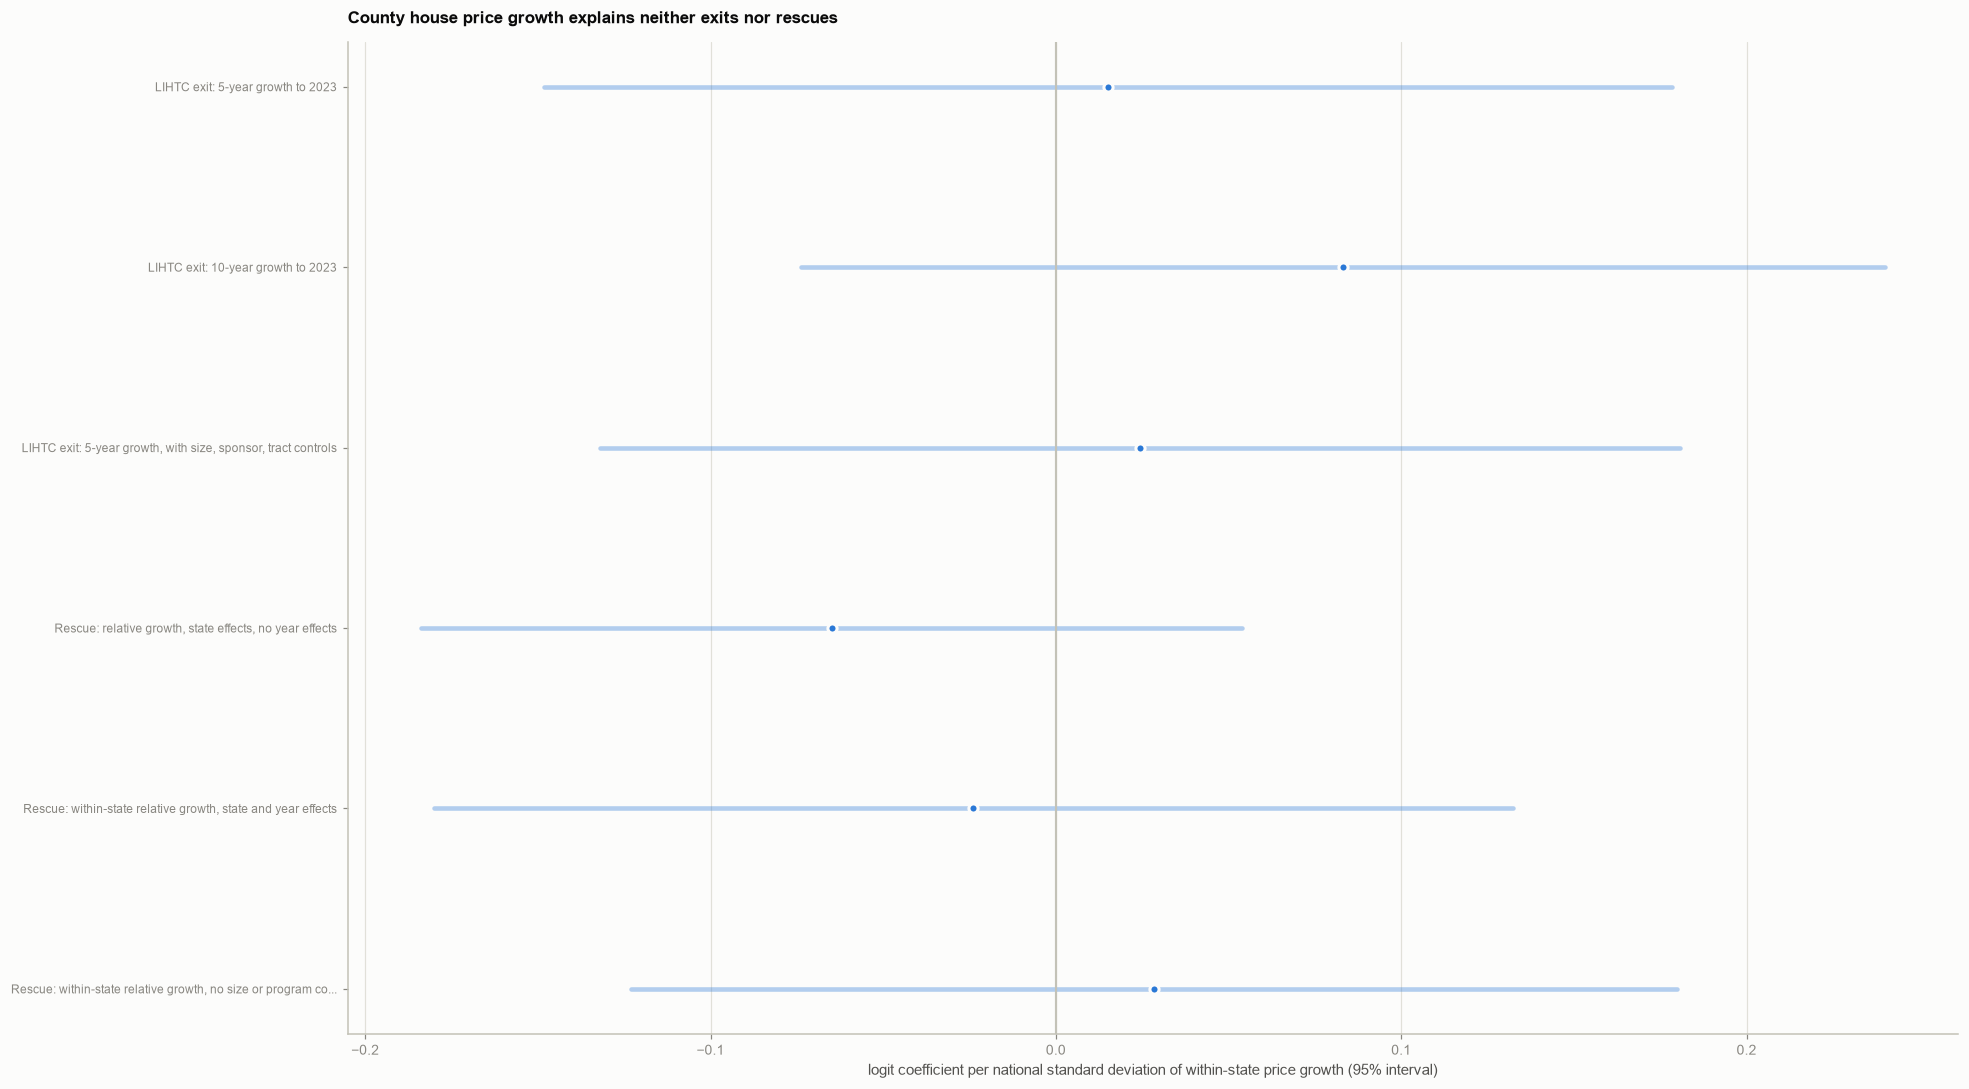

In [4]:
rows = [("LIHTC exit: " + k, v) for k, v in lih.iterrows()] + [("Rescue: " + k, v) for k, v in res.iterrows()]
fig, ax = plt.subplots(figsize=(18, 10))
for i, (lab, r) in enumerate(rows):
    est, se = r["coef"], r["se"]
    ax.plot([est - 1.96 * se, est + 1.96 * se], [i, i], color=SERIES[0], alpha=0.35, lw=3, solid_capstyle="round")
    dot(ax, est, i, SERIES[0])
ax.axvline(0, color=BASELINE, lw=1.4)
ax.set_yticks(range(len(rows)), [l if len(l) < 62 else l[:59] + "..." for l, _ in rows], fontsize=8); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("logit coefficient per national standard deviation of within-state price growth (95% interval)")
ax.set_title("County house price growth explains neither exits nor rescues", fontsize=11, loc="left")
fig.tight_layout()
save_figure(fig, "56_price_growth_coefficients", part="05_preservation")
plt.show()

## 3. The other Begley and Reina factor: nonprofit sponsorship (LIHTC only)

Their second driver is for-profit ownership. NHPD only holds the current owner (a snapshot, so unusable as of the event, Part 5e), but the HUD LIHTC file records whether a nonprofit sponsors the project at placement, which is valid as of the decision. 1,507 of the 7,315 projects have no sponsor flag and are kept as a separate category.

In [5]:
flag = raw.non_prof.reindex(c.index)      # the earlier cell filled the missing flags with 0, so read the original again
c["np"] = flag.fillna(0.0); c["miss_np"] = flag.isna().astype(float)
print("share left monitoring: nonprofit", round(c[flag == 1].left_monitoring.mean(), 3), "| for-profit", round(c[flag == 0].left_monitoring.mean(), 3), "| no flag", round(c[flag.isna()].left_monitoring.mean(), 3))
ok = c.groupby("state_fips").agg(a=("miss_np", "mean"), b=("np", "mean"))
ok = ok[(ok.a < 1) & (ok.b < 1) & (ok.a > 0)].index     # states where both categories vary, so the dummies are not collinear with the state effects
m, n, k = fe_logit(c[c.state_fips.isin(ok)], "g5", ("np", "miss_np", "log_units"))
print(f"with state effects ({n} projects, {k} states): nonprofit coefficient {m.params['np']:.3f} (t {m.tvalues['np']:.2f}), odds ratio {np.exp(m.params['np']):.2f}; no-flag category {m.params['miss_np']:.3f} (t {m.tvalues['miss_np']:.2f})")

share left monitoring: nonprofit 0.45 | for-profit 0.521 | no flag 0.435
with state effects (4858 projects, 24 states): nonprofit coefficient -0.061 (t -0.49), odds ratio 0.94; no-flag category -0.082 (t -0.38)


## Findings

**House price growth is not a driver here, in either direction.** This is the main Begley and Reina result for New York's Mitchell-Lama properties; it does not carry over to national HOME and HUD rescue or to LIHTC exit.

- **Rescue (11,481 events in 36 states, 99 percent matched).** Within-state relative five-year price growth: -0.024 per standard deviation (t -0.30) with state and event-year effects, -0.065 (t -1.07) without year effects. Out of sample the AUC does not move (0.817 and 0.832 with and without price growth for logit; boosting with price growth is lower, 0.766 and 0.785). The rescue rate by within-state quintile is 1.4, 1.7, 1.7, 1.2, 1.4 percent, no trend.
- **LIHTC exit (6,530 projects in 45 states).** Five-year growth to 2023: +0.015 (t 0.18); ten-year growth +0.083 (t 1.04); with controls +0.024 (t 0.31). Out-of-sample AUC 0.787 with and without it. By quintile 43, 57, 62, 44, 42 percent, no trend.
- **Nonprofit sponsorship (LIHTC; 4,858 projects in the 24 states where both the sponsor flag and its absence vary).** Raw exit rates differ a little (nonprofit 45 percent, for-profit 52, no flag 44) but within a state the nonprofit coefficient is -0.061 (t -0.49, odds ratio 0.94), so there is no detectable effect. Begley and Reina's 59 to 62 percent lower hazard for nonprofit owners is not reproduced in this sample; the interval is wide, so a moderate effect cannot be ruled out.
- **Why the results can differ from theirs.** They model owner opt-out decisions in one city with dated events and time-varying covariates; we have an undated exit observed in 2024 (LIHTC) and a rescue outcome that is a new subsidy, not an owner choice. We also cannot test the "past all restrictions" factor: our rescue events are all past the end date by construction, and the LIHTC sample is chosen by age.

**Caveats.** The FHFA county index is less reliable in small counties (5 percent of county-years have no index, and 9 percent of LIHTC projects are in such counties); LIHTC growth windows end in 2023 whatever the decision date; 188 rescued events.